In [1]:
import cobra
import networkx as nx
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
import seaborn as sns
import os
from scipy import stats
from statsmodels.stats.multitest import  multipletests
import operator
plt.rcParams['figure.figsize'] = [11, 7]

## Standard

-0.1655988906397263


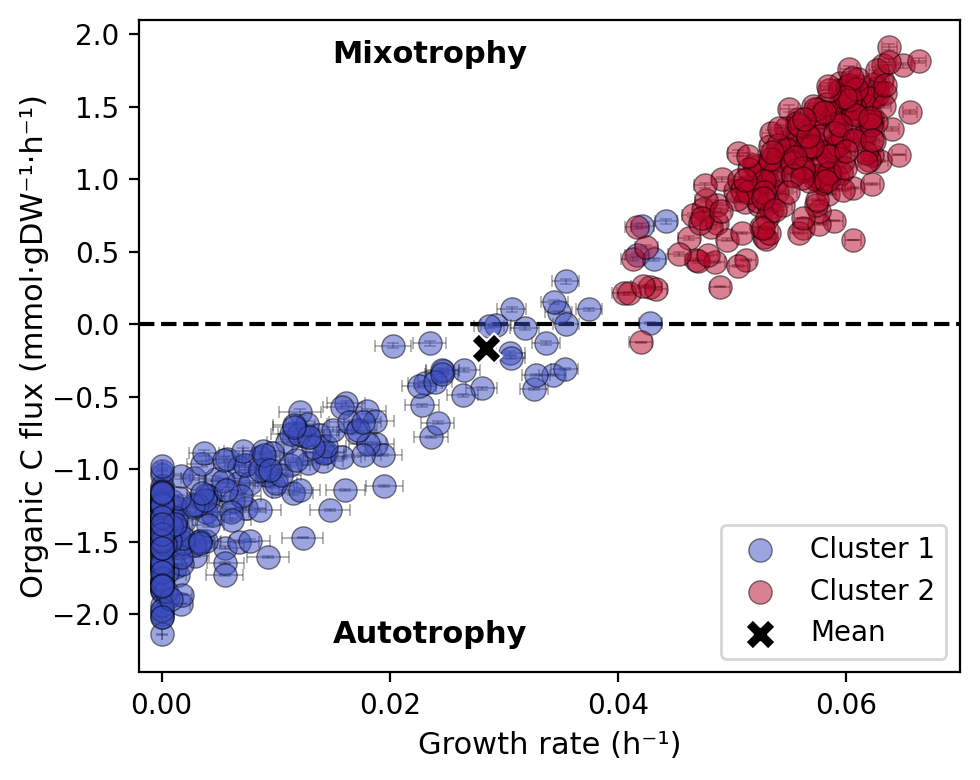

In [17]:
plt.rcParams['figure.figsize'] = [5,4]
plt.rcParams['figure.dpi'] = 200

fig, ax = plt.subplots()

means = pd.read_csv('results_new/results_std_corrected_12_toy_model_avg_PEAKS_ox.dat', sep='\t')
err = pd.read_csv('results_new/results_std_corrected_12_toy_model_std_PEAKS_ox.dat', sep='\t')

clusters = pd.read_csv('results_new/clusters_4to12h_N_NEW.dat', sep='\t')
cmap = plt.cm.coolwarm
color_peak1 = cmap(0.0)[:3] + (0.45,)   # coolwarm dark blue -> Peak 1
color_peak2 = cmap(1.0)[:3] + (0.45,)   # coolwarm dark red  -> Peak 2
colors = [color_peak1, color_peak2]

dfs_means = [means[clusters['cluster']==0], means[clusters['cluster']==1]]
dfs_err = [err[clusters['cluster']==0], err[clusters['cluster']==1]]

labels = ['Cluster 1', 'Cluster 2']

# error bars (dibujadas debajo de los puntos)
for i in range(0,2):
    ax.errorbar(
        dfs_means[i]['growth'], dfs_means[i]['ac'],
        xerr=dfs_err[i]['growth'], yerr=dfs_err[i]['ac'],
        fmt='none',
        ecolor='black',
        elinewidth=0.6,
        capsize=2,
        capthick=0.6,
        alpha=0.35,
        zorder=2,
    )
    
    # scatter
    sc = ax.scatter(
        dfs_means[i]['growth'], dfs_means[i]['ac'],
        edgecolor='black', linewidths=0.5,
        alpha=0.5, s=70,
        color=colors[i],
        label=labels[i],
        zorder=3,
    )

# =========================================================
# MEAN POINT (centroid)
# =========================================================
mean_growth = means['growth'].mean()
mean_ac = means['ac'].mean()

mean_pt = ax.scatter(
    mean_growth, mean_ac,
    marker='X', s=120,
    color='black',
    edgecolor='white',
    linewidths=0.8,
    zorder=5,
    label='Mean'
)

ax.set_xlim(-0.002, 0.07)
ax.set_ylim(-2.4, 2.1)

print(mean_ac)
# --- shaded regions ---
#prod = ax.axhspan(0, ax.get_ylim()[1], color='tab:red', alpha=0.12, label='Consumption')
#cons = ax.axhspan(ax.get_ylim()[0], 0, color='tab:blue', alpha=0.12, label='Production')

# zero line
ax.axhline(0, color='black', linestyle='dashed')

ax.set_xlabel('Growth rate (h⁻¹)', fontsize=11)
ax.set_ylabel('Organic C flux (mmol·gDW⁻¹·h⁻¹)', labelpad=1, fontsize=11)
ax.set_xticks([0, 0.02, 0.04, 0.06])

# legend (now includes mean)
ax.legend(frameon=True, loc='lower right')

plt.text(0.015,-2.2, 'Autotrophy', fontsize=11, weight=600)
plt.text(0.015,1.8, 'Mixotrophy', fontsize=11, weight=600)

plt.tight_layout()
plt.savefig('orgC_vs_growth.png', format='png', dpi=200)
plt.show()

In [12]:
means

,C,O2,photons,ac,growth,n
0,1.948179,0.041683,22.987729,0.580263,0.060653,0.826900
1,2.227050,0.588670,21.975861,0.667831,0.056249,0.926153
2,2.532237,1.015061,20.239184,-1.113878,0.009837,0.425351
3,2.606429,1.328259,19.465911,-0.766908,0.012470,0.468042
4,2.810133,1.328891,20.437260,-0.954352,0.012851,0.453945
...,...,...,...,...,...,...
515,2.516049,0.967061,20.167429,-1.381136,0.004094,0.570559
516,2.441441,1.062329,19.334759,-1.378906,0.000005,0.269305
517,2.547117,1.129764,21.216184,0.787810,0.053784,1.039095
518,2.742121,1.197904,20.187125,-1.544012,0.000005,0.364886


-0.1655988906397263


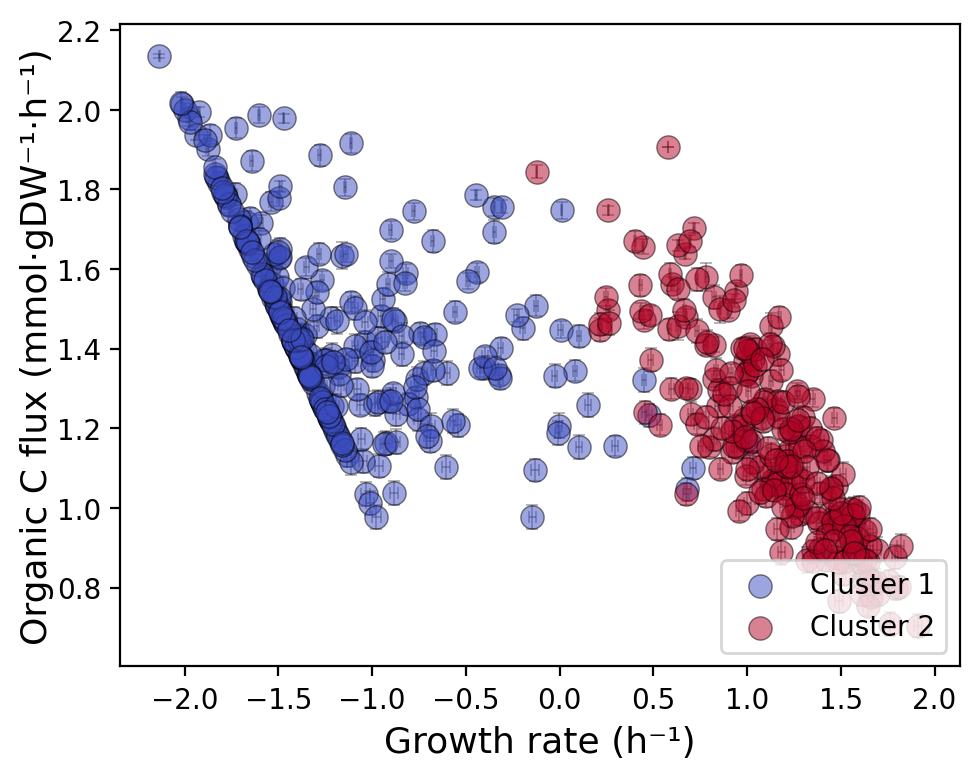

In [9]:
plt.rcParams['figure.figsize'] = [5,4]
plt.rcParams['figure.dpi'] = 200

fig, ax = plt.subplots()

means = pd.read_csv('results_new/results_std_corrected_12_toy_model_avg_PEAKS_ox.dat', sep='\t')
err = pd.read_csv('results_new/results_std_corrected_12_toy_model_std_PEAKS_ox.dat', sep='\t')

clusters = pd.read_csv('results_new/clusters_4to12h_N_NEW.dat', sep='\t')
cmap = plt.cm.coolwarm
color_peak1 = cmap(0.0)[:3] + (0.45,)   # coolwarm dark blue -> Peak 1
color_peak2 = cmap(1.0)[:3] + (0.45,)   # coolwarm dark red  -> Peak 2
colors = [color_peak1, color_peak2]

dfs_means = [means[clusters['cluster']==0], means[clusters['cluster']==1]]
dfs_err = [err[clusters['cluster']==0], err[clusters['cluster']==1]]

labels = ['Cluster 1', 'Cluster 2']

# error bars (dibujadas debajo de los puntos)
for i in range(0,2):
    ax.errorbar(
        dfs_means[i]['ac'], dfs_means[i]['C']-dfs_means[i]['O2'],
        xerr=dfs_err[i]['ac'], yerr=dfs_err[i]['O2'],
        fmt='none',
        ecolor='black',
        elinewidth=0.6,
        capsize=2,
        capthick=0.6,
        alpha=0.35,
        zorder=2,
    )
    
    # scatter
    sc = ax.scatter(
        dfs_means[i]['ac'],  dfs_means[i]['C']-dfs_means[i]['O2'],
        edgecolor='black', linewidths=0.5,
        alpha=0.5, s=70,
        color=colors[i],
        label=labels[i],
        zorder=3,
    )

# =========================================================
# MEAN POINT (centroid)
# =========================================================
#mean_growth = means['growth'].mean()
#mean_ac = means['ac'].mean()
#
#mean_pt = ax.scatter(
#    mean_growth, mean_ac,
#    marker='X', s=120,
#    color='black',
#    edgecolor='white',
#    linewidths=0.8,
#    zorder=5,
#    label='Mean'
#)

#ax.set_xlim(-0.002, 0.07)
#ax.set_ylim(-2.4, 2.1)

print(mean_ac)
# --- shaded regions ---
#prod = ax.axhspan(0, ax.get_ylim()[1], color='tab:red', alpha=0.12, label='Consumption')
#cons = ax.axhspan(ax.get_ylim()[0], 0, color='tab:blue', alpha=0.12, label='Production')

# zero line
#ax.axhline(0, color='black', linestyle='dashed')

ax.set_xlabel('Growth rate (h⁻¹)', fontsize=13)
ax.set_ylabel('Organic C flux (mmol·gDW⁻¹·h⁻¹)', labelpad=1, fontsize=13)
#ax.set_xticks([0, 0.02, 0.04, 0.06])

# legend (now includes mean)
ax.legend(frameon=True, loc='lower right')

#plt.text(0.015,-2.2, 'Autotrophy', fontsize=13, weight=600)
#plt.text(0.015,1.8, 'Mixotrophy', fontsize=13, weight=600)

plt.tight_layout()
plt.savefig('orgC_vs_growth.png', format='png', dpi=200)
plt.show()

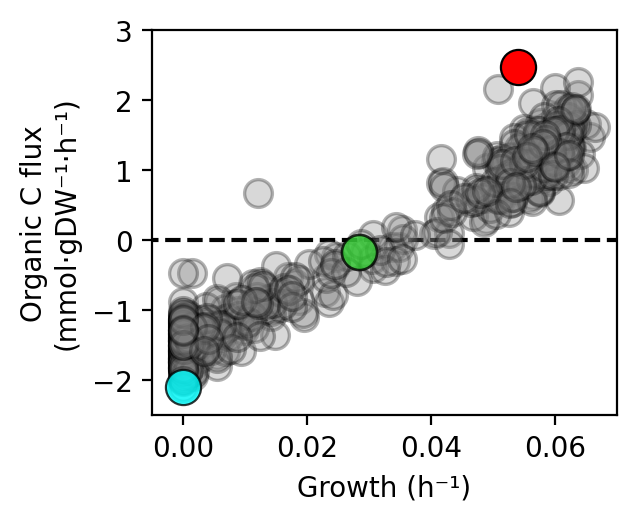

In [11]:
plt.rcParams['figure.figsize'] = [3,2.5]
plt.rcParams['figure.dpi'] = 200



means = pd.read_csv('results_new/results_std_corrected_12_toy_model_avg_PEAKS.dat', sep='\t')
index_producer = int(means[means['ac']==min(means['ac'])].index[0])

index_consumer = int(means[means['ac']==max(means['ac'])].index[0])



#sc = plt.scatter(means['growth'], means['ac'], c=means['C'],    cmap="RdBu_r",
#    edgecolor='black', linewidths=0.5, alpha=0.9, s=50)
sc = plt.scatter(means['growth'], means['ac'],
    edgecolor='black', linewidths=1.2, alpha=0.3, s=100, color='grey')

plt.scatter(means['growth'][index_consumer], means['ac'][index_consumer], 
            color='red', s=160, linewidths=0.8,edgecolor='black')

plt.scatter(means['growth'][index_producer], means['ac'][index_producer], 
            color='cyan', s=160, linewidths=0.8,edgecolor='black', alpha=0.8)


plt.scatter([np.mean(means['growth'])], np.mean(means['ac']), 
            color='limegreen', s=160, linewidths=0.95,edgecolor='black', alpha=0.8)


plt.plot([-0.01,6.2], [0,0], color='black', linestyle='dashed', zorder=-1)
#cbar = plt.colorbar(sc,  pad=0.01)
plt.ylim(-2.5, 3)
plt.xlim(-0.005,0.07)
plt.xlabel('Growth (h⁻¹)')
plt.ylabel('Organic C flux\n(mmol·gDW⁻¹·h⁻¹)')
plt.xticks([0, 0.02,  0.04, 0.06])
plt.savefig('metabolic_map_plot.png', format='png', dpi=200, bbox_inches='tight')

#cbar.set_label('Inorganic C flux ()')  # colorbar label

In [4]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

means = pd.read_csv('results_new/results_std_corrected_12_toy_model_avg.dat', sep='\t')
means = pd.read_csv('results_new/results_std_corrected_12_toy_model_avg_PEAKS.dat', sep='\t')

model = cobra.io.load_json_model('models/iJN678_std_aminoacids.json')

acids_set = ['EX_ac_e', 'EX_pyr_e', 'EX_fum_e', 'EX_succ_e', 'EX_cit_e', 'EX_akg_e', 'EX_mal__L_e', 'EX_lac__D_e']
acids_c = [model.reactions.get_by_id(r).reactants[0].elements['C'] for r in acids_set]
   
    
aminoacids = ['glu__L', 'ala__L', 'arg__L', 'gly', 'gln__L', 'his__L', 'leu__L','lys__L', 'pro__L', 'ser__L', 
             'phe__L', 'asn__L', 'ile__L', 'met__L', 'thr__L', 'trp__L', 'tyr__L', 'val__L', 'cys__L', 'asp__L']
aminoacids_c = [model.metabolites.get_by_id(r+'_c').elements['C'] for r in aminoacids]
aminoacids_n =  [model.metabolites.get_by_id(r+'_c').elements['N'] for r in aminoacids]

max_org_C_uptake = np.mean(means[means['ac']>0]['ac'])#/1.5
max_org_C_uptake

Set parameter Username
Set parameter LicenseID to value 2866505
Academic license - for non-commercial use only - expires 2027-09-22


In [6]:
max_org_C_uptake = np.mean(means[means['ac']>0]['ac'])#/1.5
max_org_C_uptake


np.float64(1.1279218678308758)

In [7]:
def plot_uptakes(compound, condition):
    plt.rcParams['figure.figsize'] = [9.5/1.2, 7/1.2]
    plt.rcParams['figure.dpi'] = 200
    C_carbon = 1000 * 0.5 / 12
 
    if compound.lower() == 'c':
        fig_name = 'results/u_C_std_VS_prot.jpeg'
        r_id = 'EX_hco3_e'
        u_id = 'u_C'
        label = 'HCO3 uptake (mmol/(gDW·h))'
    elif compound.lower() == 'n':
        fig_name = 'results/u_N_std_VS_prot.jpeg'
        r_id = 'EX_nh4_e'
        u_id = 'u_N'
        label = 'NH4 uptake (mmol/(gDW·h))'
    else:
        raise ValueError('Compound parameter should be either C or N')
    
    
    # POLYTOPE WITHOUT EXCHANGE

    i = 0
    n = 0
    stop = False
    u_min = []
    u_max = []
    growth = []
    optimal_value = 1
    
    if condition == 'std': 
        model_id = 'models/iJN678_std_aminoacids.json'
    else: 
        model_id = 'models/iJN678_prot.json'
        
    color12 = (0.0, 0.5, 0.5, 0.35)
    color4 = (0.8, 0.4, 0.6, 0.4)
    
    while i<=optimal_value:
        model = cobra.io.load_json_model(model_id)

        model.solver='glpk'
       # model.reactions.Diff_nh4_e.delete()
        if condition == 'std':
            model.reactions.EX_o2_e.lower_bound = -1000
            model.reactions.EX_hco3_e.lower_bound = -10
            model.reactions.EX_so4_e.lower_bound = -217 
            model.reactions.EX_nh4_e.lower_bound = -10 

            
        model.reactions.EX_glc__D_e.lower_bound = 0
        model.reactions.EX_photon_e.lower_bound = -23
        model.reactions.EX_co2_e.lower_bound = 0
        model.reactions.EX_no3_e.lower_bound = 0
    

        model.objective = model.reactions.BIOMASS_Ec_SynAuto
        optimal_value = model.optimize().objective_value
        
        model.reactions.BIOMASS_Ec_SynAuto.bounds = (i, i)
        model.objective = model.reactions.get_by_id(r_id)
    
        if not stop and model.optimize().status == 'infeasible':
            stop = n
            
        minimum = - model.optimize().objective_value
        maximum = - model.optimize(objective_sense='minimize').objective_value
        
        u_min.append(minimum)
        u_max.append(maximum)
        growth.append(i)
    
        if i!=optimal_value and i+0.05 > optimal_value:
            i = optimal_value
        else:
            i += 0.05
        n += 1
        
    opt1 = optimal_value
    print(opt1)
    
    if not stop:
        stop = len(growth)
        
    slope_std = (u_min[-1]-u_min[0])/(growth[-1]-growth[0])
    plt.plot(growth[:stop+1], u_min[:stop+1], color = color12)
    plt.plot(growth[:stop+1], u_max[:stop+1], color = color12)
    
    max_line_std_1 = [growth[:stop+1], u_max[:stop+1]]
    min_line_std_1 = [growth[:stop+1], u_min[:stop+1]]
    
    max_g_1 = max(growth)
    u_max_1 = max(u_max)
    
    
    
    # POLYTOPE WITH EXCHANGE
    i = 0
    n = 0
    stop = False
    u_min = []
    u_max = []
    growth = []
    optimal_value = 1
    
    if condition == 'std': 
        model_id = 'models/iJN678_std_aminoacids.json'
    else: 
        model_id = 'models/iJN678_prot.json'
        
        
    while i<=optimal_value:
        model = cobra.io.load_json_model(model_id)
        for r in acids_set:
            model.reactions.get_by_id(r).bounds = (-1000, 0)
        for aa in aminoacids:
            model.reactions.get_by_id('EX_'+aa+'_e').bounds = (-1000,0)

        sum_c_flux = model.problem.Constraint(
            acids_c[0]*model.reactions.get_by_id(acids_set[0]).flux_expression +
            acids_c[1]*model.reactions.get_by_id(acids_set[1]).flux_expression +
            acids_c[2]*model.reactions.get_by_id(acids_set[2]).flux_expression + 
            acids_c[3]*model.reactions.get_by_id(acids_set[3]).flux_expression + 
            acids_c[4]*model.reactions.get_by_id(acids_set[4]).flux_expression +
            acids_c[5]*model.reactions.get_by_id(acids_set[5]).flux_expression +
            acids_c[6]*model.reactions.get_by_id(acids_set[6]).flux_expression +
            acids_c[7]*model.reactions.get_by_id(acids_set[7]).flux_expression +
            aminoacids_c[0]*model.reactions.get_by_id('EX_'+aminoacids[0]+'_e').flux_expression +
            aminoacids_c[1]*model.reactions.get_by_id('EX_'+aminoacids[1]+'_e').flux_expression +
            aminoacids_c[2]*model.reactions.get_by_id('EX_'+aminoacids[2]+'_e').flux_expression +
            aminoacids_c[3]*model.reactions.get_by_id('EX_'+aminoacids[3]+'_e').flux_expression +
            aminoacids_c[4]*model.reactions.get_by_id('EX_'+aminoacids[4]+'_e').flux_expression +
            aminoacids_c[5]*model.reactions.get_by_id('EX_'+aminoacids[5]+'_e').flux_expression +
            aminoacids_c[6]*model.reactions.get_by_id('EX_'+aminoacids[6]+'_e').flux_expression +
            aminoacids_c[7]*model.reactions.get_by_id('EX_'+aminoacids[7]+'_e').flux_expression +
            aminoacids_c[8]*model.reactions.get_by_id('EX_'+aminoacids[8]+'_e').flux_expression +
            aminoacids_c[9]*model.reactions.get_by_id('EX_'+aminoacids[9]+'_e').flux_expression +
            aminoacids_c[10]*model.reactions.get_by_id('EX_'+aminoacids[10]+'_e').flux_expression +
            aminoacids_c[11]*model.reactions.get_by_id('EX_'+aminoacids[11]+'_e').flux_expression +
            aminoacids_c[12]*model.reactions.get_by_id('EX_'+aminoacids[12]+'_e').flux_expression +
            aminoacids_c[13]*model.reactions.get_by_id('EX_'+aminoacids[13]+'_e').flux_expression +
            aminoacids_c[14]*model.reactions.get_by_id('EX_'+aminoacids[14]+'_e').flux_expression +
            aminoacids_c[15]*model.reactions.get_by_id('EX_'+aminoacids[15]+'_e').flux_expression +
            aminoacids_c[16]*model.reactions.get_by_id('EX_'+aminoacids[16]+'_e').flux_expression +
            aminoacids_c[17]*model.reactions.get_by_id('EX_'+aminoacids[17]+'_e').flux_expression +
            aminoacids_c[18]*model.reactions.get_by_id('EX_'+aminoacids[18]+'_e').flux_expression +
            aminoacids_c[19]*model.reactions.get_by_id('EX_'+aminoacids[19]+'_e').flux_expression,
            lb=-max_org_C_uptake,
            ub=1000)
        model.add_cons_vars(sum_c_flux)
        
        model.solver='glpk'
       # model.reactions.Diff_nh4_e.delete()
        if condition == 'std':
            model.reactions.EX_o2_e.lower_bound = -1000
            model.reactions.EX_hco3_e.lower_bound = -10
            model.reactions.EX_so4_e.lower_bound = -217 
            model.reactions.EX_nh4_e.lower_bound = -10
     
        model.reactions.EX_glc__D_e.lower_bound = 0
        model.reactions.EX_photon_e.lower_bound = -23
        model.reactions.EX_co2_e.lower_bound = 0
        model.reactions.EX_no3_e.lower_bound = 0
        
      #  ATP_m = cobra.Reaction(id = 'ATPM', name = 'ATP maintenance', 
      #                         lower_bound=0.13, upper_bound=0.13)
      #  ATP_m.add_metabolites({model.metabolites.atp_c:-1,model.metabolites.h2o_c:-1,
      #                      model.metabolites.adp_c:1, model.metabolites.h_c:1,
      #                      model.metabolites.pi_c:1})
      #  model.add_reactions([ATP_m])
        
        model.objective = model.reactions.BIOMASS_Ec_SynMixo
        optimal_value = model.optimize().objective_value
        
        model.reactions.BIOMASS_Ec_SynMixo.bounds = (i, i)
        model.objective = model.reactions.get_by_id(r_id)
    
        if not stop and model.optimize().status == 'infeasible':
            stop = n
            
        minimum = - model.optimize().objective_value
        maximum = - model.optimize(objective_sense='minimize').objective_value
        
        u_min.append(minimum)
        u_max.append(maximum)
        growth.append(i)
    
        if i!=optimal_value and i+0.05 > optimal_value:
            i = optimal_value
        else:
            i += 0.05
            
        n += 1
    
    opt2 = optimal_value
    
    if not stop:
        stop = len(growth)
        
    slope_std = (u_min[-1]-u_min[0])/(growth[-1]-growth[0])
    plt.plot(growth[:stop+1], u_min[:stop+1], color = 'indianred')
    #plt.plot(growth[:stop+1], u_max[:stop+1], color = 'indianred')
    
    max_line_std_2 = [growth[:stop+1], u_max[:stop+1]]
    min_line_std_2 = [growth[:stop+1], u_min[:stop+1]]
    
    max_g_1 = max(growth)
    u_max_1 = max(u_max)
    


    means_toy = pd.read_csv('results_new/results_std_corrected_12_toy_model_avg_PEAKS_ox.dat', sep='\t')
    stds_toy = pd.read_csv('results_new/results_std_corrected_12_toy_model_std_PEAKS_ox.dat', sep='\t')

    clusters = pd.read_csv('results_new/clusters_4to12h_N_NEW.dat',sep='\t')
    
    mean_dfs = [means_toy[clusters['cluster']==0], means_toy[clusters['cluster']==1]]
    sd_dfs = [stds_toy[clusters['cluster']==0], stds_toy[clusters['cluster']==1]]
    
    cmap = plt.cm.coolwarm
    color_peak1 = cmap(0.0)[:3] + (0.45,)   # coolwarm dark blue -> Peak 1
    color_peak2 = cmap(1.0)[:3] + (0.45,)   # coolwarm dark red  -> Peak 2
    colors = [color_peak1, color_peak2]
    
    avg_x = []
    avg_y = []
    for n,df in enumerate(mean_dfs):

       # plt.errorbar([abs(cell[1]['BIOMASS_Ec_SynMixo']) for i,cell in enumerate(list(df.iterrows()))], 
       #              [abs(cell[1]['EX_hco3_e']) for i,cell in enumerate(list(df.iterrows()))],
       #           xerr = sd_dfs[n]['BIOMASS_Ec_SynMixo'], yerr = sd_dfs[n]['EX_hco3_e'],
       #              elinewidth=0.6,  marker = 'o', ecolor = 'black', barsabove=False,
       #          markersize = 12, capsize=1, linestyle = 'None', label = 'Cluster '+ str(n+1), color = color12)
        plt.errorbar([abs(cell[1]['growth']) for i,cell in enumerate(list(df.iterrows()))], 
                     [abs(cell[1]['C']) for i,cell in enumerate(list(df.iterrows()))],
                  xerr = sd_dfs[n]['growth'], yerr = sd_dfs[n]['C'], 
                     elinewidth=0.6,  marker = 'o', ecolor = 'black', barsabove=False,
                 markersize = 12, capsize=1, linestyle = 'None', label = 'Cluster '+ str(n+1), color = colors[n],
                        markeredgecolor='black', markeredgewidth=0.5  )

    print(avg_x, avg_y)
    #plt.scatter([np.mean(avg_x)], [np.mean(avg_y)], color='black', s=50, marker='o', label='Average')


    plt.xlim((0,0.085))
    if condition == 'std':
        if compound == 'C':
            plt.ylim((0,4))
            plt.plot(np.linspace(opt1, opt1,100), np.linspace(1.98,10,100), color = color12)
            plt.plot(np.linspace(opt2,opt2,100), np.linspace(2.02,10,100), color = 'indianred')
            #plt.legend(fontsize=16,loc='upper left')

        else: 
            plt.ylim((0,0.6))
            plt.plot(np.linspace(optimal_value,opt1,100), np.linspace(0.155,0.6,100), color = color12)
            plt.plot(np.linspace(optimal_value,opt2,100), np.linspace(0.155,0.6,100), color = 'indianred')
            #plt.legend(fontsize=16,loc='upper right')

    
    plt.fill_between(min_line_std_1[0], min_line_std_1[1], 10, color = color12,alpha=0.1)
    plt.fill_between(min_line_std_2[0], min_line_std_2[1], 10, color = 'indianred',alpha=0.1)
    plt.xlabel('Growth rate (h⁻¹)', fontsize=17)
    plt.ylabel('Inorganic C flux (mmol·gDW⁻¹·h⁻¹)', fontsize=17)
   # plt.legend(fontsize=16,loc='upper right')
    #plt.savefig(fig_name, dpi=100)

    exchange_handles = [
        plt.Line2D([0], [0], marker='s', color='w', markerfacecolor=color12, markersize=16, alpha=0.6),
        plt.Line2D([0], [0], marker='s', color='w', markerfacecolor='indianred', markersize=16, alpha=0.6),
    ]
    exchange_labels = ['No exchange', 'Exchange']
    cluster_handles, cluster_labels = plt.gca().get_legend_handles_labels()
    plt.legend(
        exchange_handles + cluster_handles,
        exchange_labels + cluster_labels,
        loc=(0.46, 0.025), fontsize=12, ncols=2
    )
    
    plt.xticks(fontsize=16, rotation=10)
    plt.yticks(fontsize=16)
    plt.savefig('new_polytope.png', format='png', dpi=200)
   # plt.savefig(fig_name, dpi=100)
    plt.show()
    
    #return slope_std, max_line_std, min_line_std

0.0481000082413763


/home/arianferrero/.local/lib/python3.10/site-packages/cobra/util/solver.py:554: UserWarning: Solver status is 'infeasible'.
  warn(f"Solver status is '{status}'.", UserWarning)


[] []


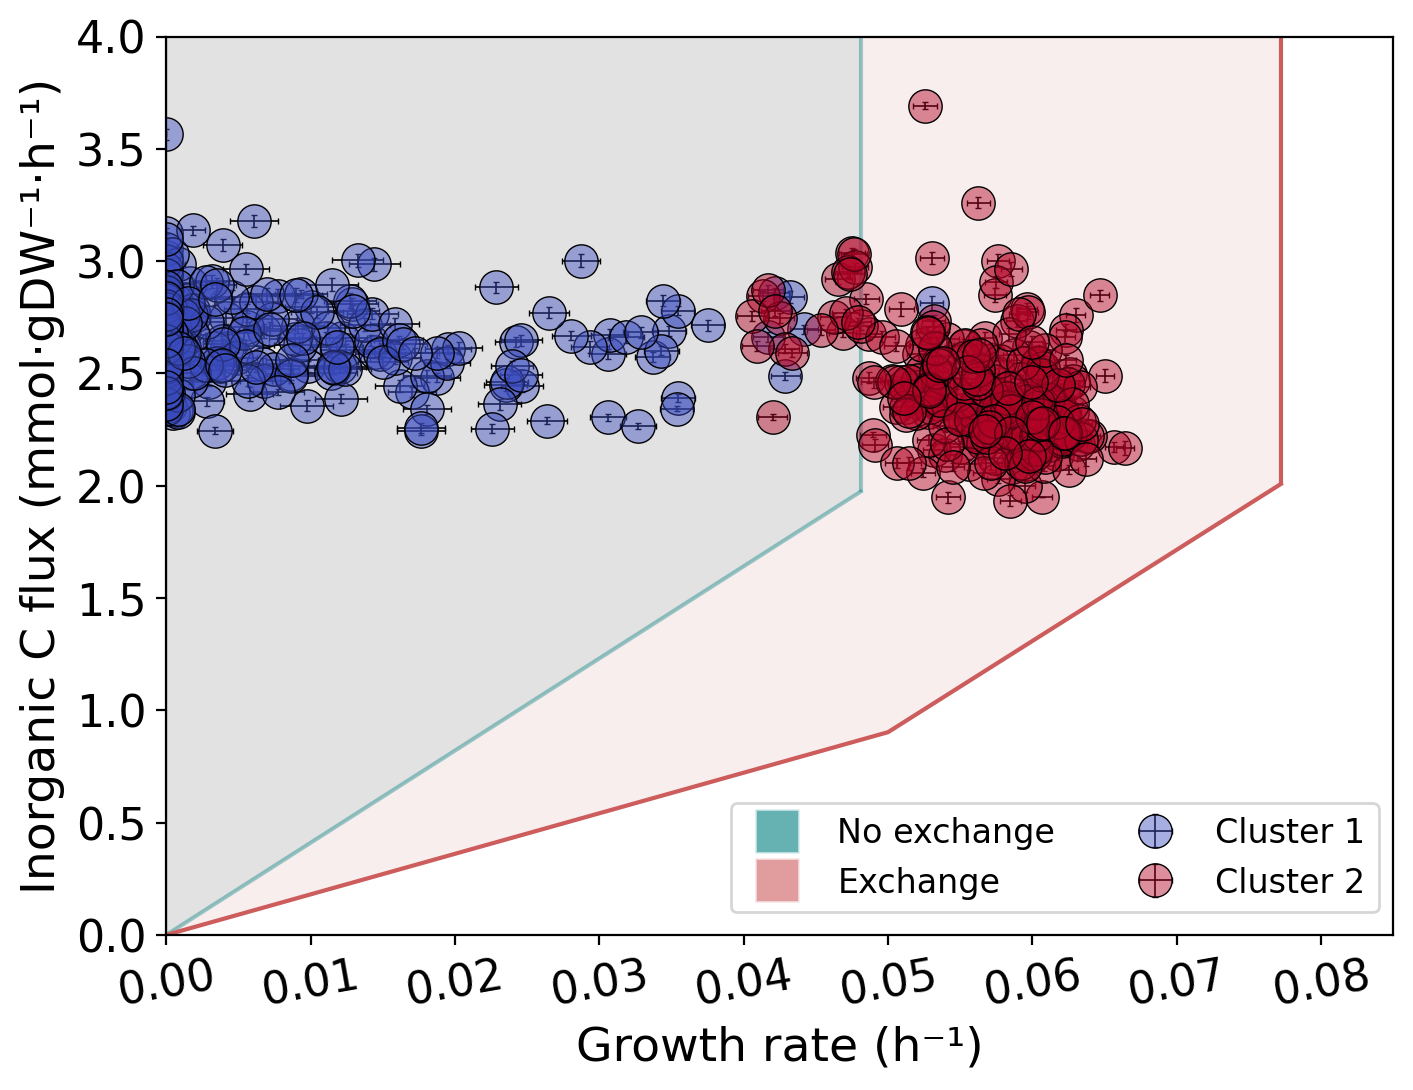

In [8]:
plot_uptakes('C', 'std')

/tmp/ipykernel_21839/1666334130.py:55: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  sc = plt.scatter(means_toy[clusters['cluster']==0]['ac'],
/tmp/ipykernel_21839/1666334130.py:59: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  sc = plt.scatter(means_toy[clusters['cluster']==1]['ac'],


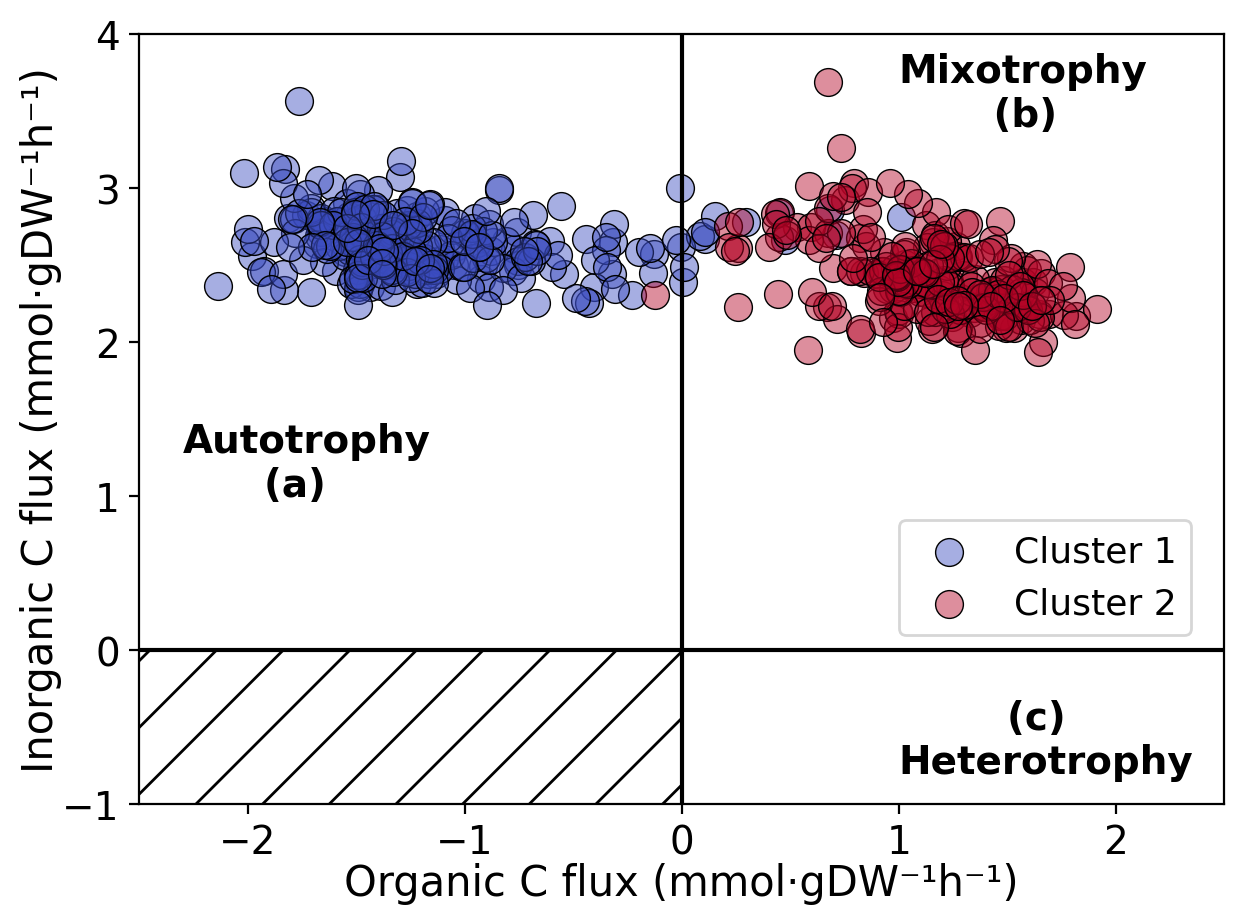

In [5]:
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from matplotlib.colors import LinearSegmentedColormap


#plt.rcParams['figure.figsize'] = [9.5/1.5, 7/1.5]
plt.rcParams['figure.figsize'] = [7,5]
plt.rcParams['figure.dpi'] = 200

clusters = pd.read_csv('results_new/clusters_4to12h_N_NEW.dat', sep='\t')
cmap = plt.cm.coolwarm
color_peak1 = cmap(0.0)[:3] + (0.45,)   # coolwarm dark blue -> Peak 1
color_peak2 = cmap(1.0)[:3] + (0.45,)   # coolwarm dark red  -> Peak 2
colors = [color_peak1, color_peak2]
labels = ['Cluster 1', 'Cluster 2']


j=0
means = pd.read_csv('results_new/genome_scale_samples_PEAKS_RuBisCO_ox/std_sampling_exchange_averages.dat', sep='\t')
stds = pd.read_csv('results_new/genome_scale_samples_PEAKS_RuBisCO_ox/std_sampling_exchange_stds.dat', sep='\t')

means_toy = pd.read_csv('results_new/results_std_corrected_12_toy_model_avg_PEAKS_ox.dat', sep='\t')
stds_toy = pd.read_csv('results_new/results_std_corrected_12_toy_model_std_PEAKS_ox.dat', sep='\t')


aminoacid_C_flux = []
total_C_uptake = []
acid_C_flux = []
for cell in means.iterrows():
    fluxes = cell[1]
    summ = np.sum([fluxes['EX_'+aa+'_e']*aminoacids_c[i] for i,aa in enumerate(aminoacids)])
    aminoacid_C_flux.append(summ)
    
    summ_ac = np.sum([fluxes[a]*acids_c[i] for i,a in enumerate(acids_set)])
    acid_C_flux.append(summ_ac)
    
    total_C_uptake.append(fluxes['EX_hco3_e'] + min(0,summ) + min(0,summ_ac))
    
#cmap = LinearSegmentedColormap.from_list("custom", ['purple', "darkblue", 'springgreen', "yellow"], N=100)
cmap = LinearSegmentedColormap.from_list("custom", [ "darkblue", 'cornflowerblue', "coral","red", "darkred"], N=100)
#cmap = LinearSegmentedColormap.from_list("custom", [  'white','#fffd8e', "orange",'red', "darkred"], N=100)

# Create a truncated version of the viridis colormap (removing dark blue tones)
def truncate_colormap(cmap, min_val=0.2, max_val=1.0, n=100):
    return LinearSegmentedColormap.from_list(
        'truncated_cmap', cmap(np.linspace(min_val, max_val, n))
    )

cmap = 'coolwarm'
cmap='RdBu_r'

# Scatter plot with color gradient
x = -np.array(acid_C_flux)-np.array(aminoacid_C_flux)

sc = plt.scatter(means_toy[clusters['cluster']==0]['ac'], 
                 means_toy[clusters['cluster']==0]['C'], color=color_peak1,
                 cmap=cmap, edgecolor='black', s=100, label=labels[0], linewidth=0.5)

sc = plt.scatter(means_toy[clusters['cluster']==1]['ac'], 
                 means_toy[clusters['cluster']==1]['C'], color=color_peak2,
                 cmap=cmap, edgecolor='black', s=100, label=labels[1], linewidth=0.5)

plt.plot(np.linspace(-3, 10,10),
         np.linspace(0,0,10), color='black', linestyle='solid', linewidth=1.5)
plt.plot(np.linspace(0,0,10), np.linspace(-3,10,10),
          color='black', linestyle='solid', linewidth=1.5)

#plt.fill_between([-0.4, 0], [0, 0],  1, color = 'green',alpha=0.2)
#plt.fill_between([0, 0.8], [0, 0],  1, color = 'purple',alpha=0.2)
#plt.fill_between([0, 0.8], [0,0], y2=[-0.2, -0.2],  color = 'red',alpha=0.3)
plt.fill_between([-0.4, 0], [0, 0],  1, color = 'white',alpha=0.2)
plt.fill_between([0, 0.8], [0, 0],  1, color = 'white',alpha=0.2)
plt.fill_between([0, 0.8], [0,0], y2=[-0.2, -0.2],  color = 'white',alpha=0.3)
plt.fill_between([-3, 0], [0,0], y2=[-1, -1],   facecolor='none', edgecolor='black', hatch='/' )
plt.text(-2.3,1,'Autotrophy\n      (a)', fontsize=14, weight=600)
plt.text(1,3.4,'Mixotrophy\n       (b)', fontsize=14, weight=600)
plt.text(1,-0.8,'        (c)\nHeterotrophy', fontsize=14, weight=600)
#plt.text(-2.5,-0.9,'Non viable', fontsize=18, weight=600)

#plt.fill_between(min_line_std_1[0], min_line_std_1[1], 1, color = 'blue',alpha=0.1)

    

plt.xlim(-2.5,2.5)
plt.ylim(-1, 4)
plt.xticks(fontsize=14, rotation=0)
plt.yticks(fontsize=14)
#plt.title(r, fontsize=17, y=0.87)
plt.legend(fontsize=13, loc=(0.7,0.22))
plt.xlabel('Organic C flux (mmol·gDW⁻¹h⁻¹)', fontsize=15,y=0.5, labelpad=0.1 )
plt.ylabel('Inorganic C flux (mmol·gDW⁻¹h⁻¹)', fontsize=15, labelpad=0.1)
plt.savefig('map_metabolisms.png', format='png', dpi=200)
plt.show()


/tmp/ipykernel_21839/1877351308.py:55: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  sc = plt.scatter(means_toy[clusters['cluster']==0]['ac'],
/tmp/ipykernel_21839/1877351308.py:59: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  sc = plt.scatter(means_toy[clusters['cluster']==1]['ac'],


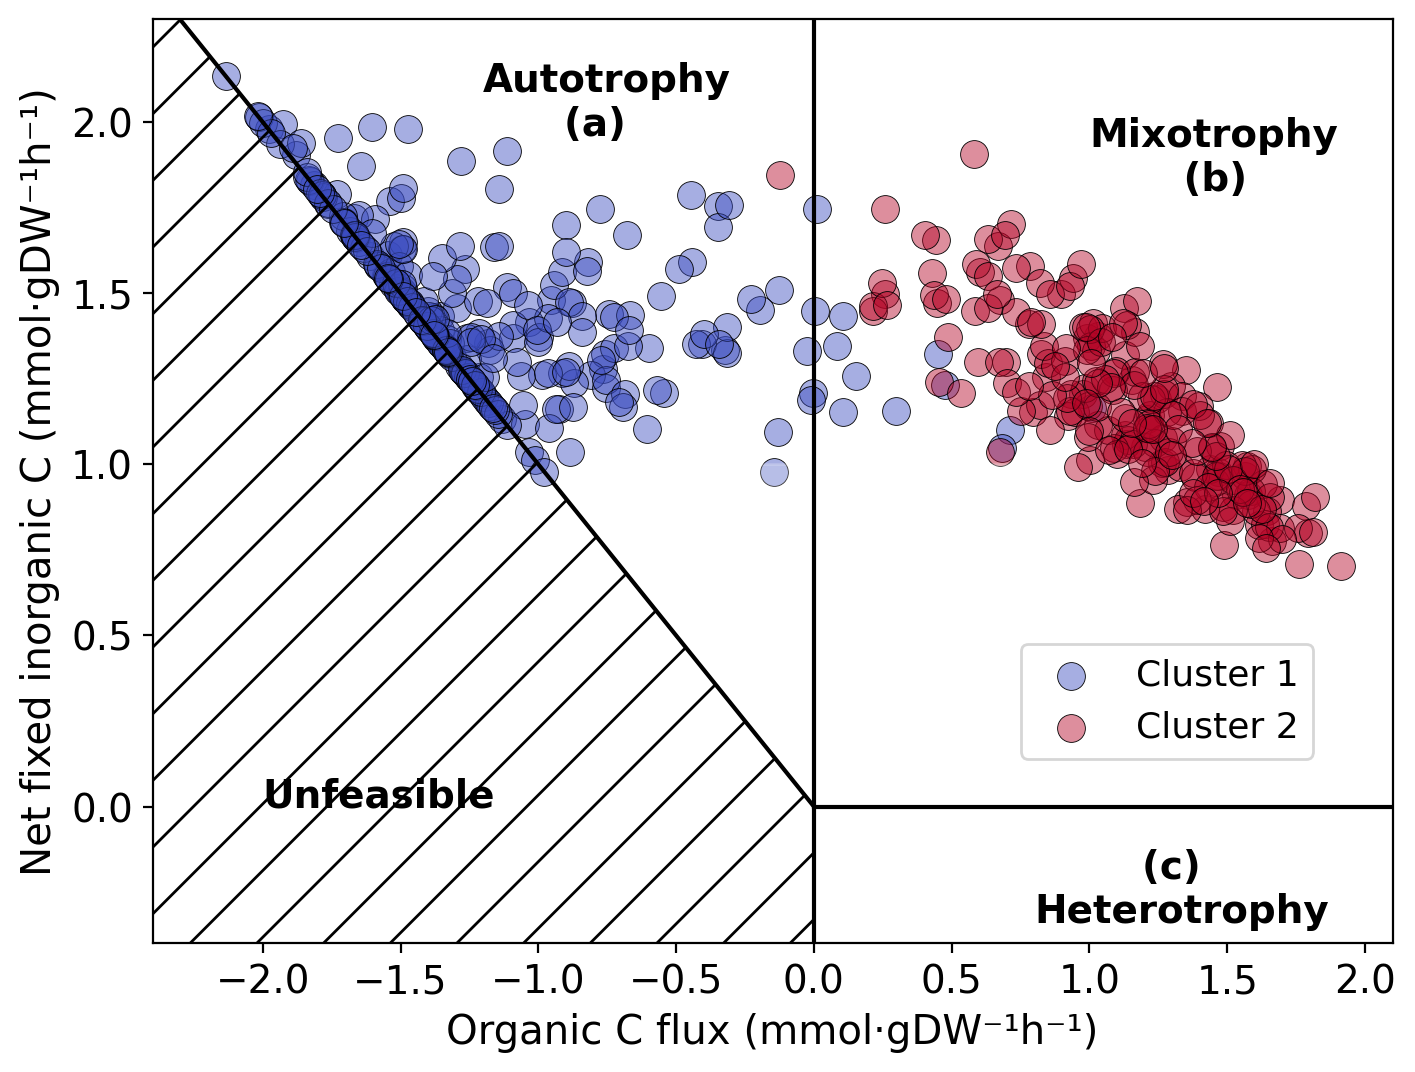

In [15]:
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from matplotlib.colors import LinearSegmentedColormap


#plt.rcParams['figure.figsize'] = [9.5/1.5, 7/1.5]
plt.rcParams['figure.figsize'] = [8,6]
plt.rcParams['figure.dpi'] = 200

clusters = pd.read_csv('results_new/clusters_4to12h_N_NEW.dat', sep='\t')
cmap = plt.cm.coolwarm
color_peak1 = cmap(0.0)[:3] + (0.45,)   # coolwarm dark blue -> Peak 1
color_peak2 = cmap(1.0)[:3] + (0.45,)   # coolwarm dark red  -> Peak 2
colors = [color_peak1, color_peak2]
labels = ['Cluster 1', 'Cluster 2']


j=0
means = pd.read_csv('results_new/genome_scale_samples_PEAKS_RuBisCO_ox/std_sampling_exchange_averages.dat', sep='\t')
stds = pd.read_csv('results_new/genome_scale_samples_PEAKS_RuBisCO_ox/std_sampling_exchange_stds.dat', sep='\t')

means_toy = pd.read_csv('results_new/results_std_corrected_12_toy_model_avg_PEAKS_ox.dat', sep='\t')
stds_toy = pd.read_csv('results_new/results_std_corrected_12_toy_model_std_PEAKS_ox.dat', sep='\t')


aminoacid_C_flux = []
total_C_uptake = []
acid_C_flux = []
for cell in means.iterrows():
    fluxes = cell[1]
    summ = np.sum([fluxes['EX_'+aa+'_e']*aminoacids_c[i] for i,aa in enumerate(aminoacids)])
    aminoacid_C_flux.append(summ)
    
    summ_ac = np.sum([fluxes[a]*acids_c[i] for i,a in enumerate(acids_set)])
    acid_C_flux.append(summ_ac)
    
    total_C_uptake.append(fluxes['EX_hco3_e'] + min(0,summ) + min(0,summ_ac))
    
#cmap = LinearSegmentedColormap.from_list("custom", ['purple', "darkblue", 'springgreen', "yellow"], N=100)
cmap = LinearSegmentedColormap.from_list("custom", [ "darkblue", 'cornflowerblue', "coral","red", "darkred"], N=100)
#cmap = LinearSegmentedColormap.from_list("custom", [  'white','#fffd8e', "orange",'red', "darkred"], N=100)

# Create a truncated version of the viridis colormap (removing dark blue tones)
def truncate_colormap(cmap, min_val=0.2, max_val=1.0, n=100):
    return LinearSegmentedColormap.from_list(
        'truncated_cmap', cmap(np.linspace(min_val, max_val, n))
    )

cmap = 'coolwarm'
cmap='RdBu_r'

# Scatter plot with color gradient
x = -np.array(acid_C_flux)-np.array(aminoacid_C_flux)

sc = plt.scatter(means_toy[clusters['cluster']==0]['ac'], 
                 means_toy[clusters['cluster']==0]['C']-means_toy[clusters['cluster']==0]['O2'], color=color_peak1,
                 cmap=cmap, edgecolor='black', s=100, label=labels[0], linewidth=0.3)

sc = plt.scatter(means_toy[clusters['cluster']==1]['ac'], 
                 means_toy[clusters['cluster']==1]['C']-means_toy[clusters['cluster']==1]['O2'], color=color_peak2,
                 cmap=cmap, edgecolor='black', s=100, label=labels[1], linewidth=0.3)

plt.plot(np.linspace(0, 10,10),
         np.linspace(0,0,10), color='black', linestyle='solid', linewidth=1.5)
plt.plot(np.linspace(0,0,10), np.linspace(-3,10,10),
          color='black', linestyle='solid', linewidth=1.5)
plt.plot([-2.4, 0,],[2.4,0],
          color='black', linestyle='solid', linewidth=1.5)

#plt.fill_between([-0.4, 0], [0, 0],  1, color = 'green',alpha=0.2)
#plt.fill_between([0, 0.8], [0, 0],  1, color = 'purple',alpha=0.2)
#plt.fill_between([0, 0.8], [0,0], y2=[-0.2, -0.2],  color = 'red',alpha=0.3)
plt.fill_between([-0.4, 0], [0, 0],  1, color = 'white',alpha=0.2)
plt.fill_between([0, 0.8], [0, 0],  1, color = 'white',alpha=0.2)
plt.fill_between([0, 0.8], [0,0], y2=[-0.2, -0.2],  color = 'white',alpha=0.3)
plt.fill_between([-2.4, 0], [2.4,0], y2=[-1, -1],   facecolor='none', edgecolor='black', hatch='/' )
plt.text(-1.2,1.96,'Autotrophy\n      (a)', fontsize=14, weight=600)
plt.text(1,1.8,'Mixotrophy\n       (b)', fontsize=14, weight=600)
plt.text(0.8,-0.34,'        (c)\nHeterotrophy', fontsize=14, weight=600)
plt.text(-2,0,'Unfeasible', fontsize=14, weight=600)

#plt.fill_between(min_line_std_1[0], min_line_std_1[1], 1, color = 'blue',alpha=0.1)

    

plt.xlim(-2.4,2.1)
plt.ylim(-0.4, 2.3)
plt.xticks(fontsize=14, rotation=0)
plt.yticks(fontsize=14)
#plt.title(r, fontsize=17, y=0.87)
plt.legend(fontsize=13, loc=(0.7,0.2))
plt.xlabel('Organic C flux (mmol·gDW⁻¹h⁻¹)', fontsize=14.5,y=0.5 )
plt.ylabel('Net fixed inorganic C (mmol·gDW⁻¹h⁻¹)', fontsize=14.5
          )
plt.savefig('map_metabolisms.png', format='png', dpi=200)
plt.show()
